# Gray-Level Co-occurrence Matrix (GLCM) & Haralick Texture Features (NumPy Only)
**Objective:** Compute the symmetric normalized **Gray-Level Co-occurrence Matrix (GLCM)** $P(i, j)$ for specified spatial offsets $(d, \theta)$ and extract the classical **Haralick Texture Descriptors** purely using **NumPy**:
1. **Contrast:** $\sum_{i,j} (i - j)^2 P(i, j)$
2. **Dissimilarity:** $\sum_{i,j} |i - j| P(i, j)$
3. **Homogeneity (Inverse Difference Moment):** $\sum_{i,j} \frac{P(i, j)}{1 + (i - j)^2}$
4. **Angular Second Moment (ASM) & Energy:** $\text{ASM} = \sum_{i,j} P(i, j)^2, \quad \text{Energy} = \sqrt{\text{ASM}}$
5. **Entropy:** $-\sum_{i,j} P(i, j) \log_2(P(i, j) + \epsilon)$
6. **Correlation:** $\sum_{i,j} \frac{(i - \mu_i)(j - \mu_j) P(i, j)}{\sigma_i \sigma_j}$

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Create three 128x128 synthetic texture patches (quantized to L = 8 gray levels: 0..7)
N = 128
LEVELS = 8
r_idx, c_idx = np.indices((N, N))

# Texture A: Smooth horizontal gradient
tex_smooth = np.clip((r_idx / N * LEVELS).astype(np.int32), 0, LEVELS - 1)

# Texture B: Fine vertical stripes (high horizontal contrast, low vertical contrast)
tex_stripes = ((c_idx % 4 < 2) * (LEVELS - 1)).astype(np.int32)

# Texture C: Random fine-grain noise (high entropy, low homogeneity)
rng = np.random.default_rng(seed=42)
tex_noise = rng.integers(0, LEVELS, size=(N, N), dtype=np.int32)


# 2. Vectorized Symmetric Normalized GLCM Computation (Pure NumPy)
def compute_glcm_numpy(image: np.ndarray, distance: int = 1, angle_deg: int = 0, levels: int = 8) -> np.ndarray:
    """
    Computes symmetric, probability-normalized GLCM of shape (levels, levels)
    for a given pixel distance d and angle theta in {0, 45, 90, 135} degrees.
    """
    angle_map = {
        0:   (0,  distance),           # East (horizontal)
        45:  (-distance, distance),    # North-East (diagonal)
        90:  (-distance, 0),           # North (vertical)
        135: (-distance, -distance),   # North-West (anti-diagonal)
    }
    if angle_deg not in angle_map:
        raise ValueError("angle_deg must be one of {0, 45, 90, 135}")

    dr, dc = angle_map[angle_deg]
    H, W = image.shape

    # Determine valid overlapping slices for source and neighbor pixels
    r_src_start = max(0, -dr)
    r_src_end   = min(H, H - dr)
    c_src_start = max(0, -dc)
    c_src_end   = min(W, W - dc)

    src = image[r_src_start:r_src_end, c_src_start:c_src_end].ravel()
    dst = image[r_src_start + dr : r_src_end + dr, c_src_start + dc : c_src_end + dc].ravel()

    # Accumulate 2D co-occurrence histogram using flat index bincount
    glcm = np.bincount(src * levels + dst, minlength=levels * levels).reshape(levels, levels).astype(np.float64)

    # Make symmetric (counts both +offset and -offset) and normalize to probabilities
    glcm = glcm + glcm.T
    glcm /= (np.sum(glcm) + 1e-12)
    return glcm


# 3. Extract Haralick Texture Properties from Normalized GLCM
def extract_haralick_features(glcm: np.ndarray) -> dict:
    levels = glcm.shape[0]
    i, j = np.meshgrid(np.arange(levels), np.arange(levels), indexing="ij")

    contrast      = np.sum(glcm * ((i - j) ** 2))
    dissimilarity = np.sum(glcm * np.abs(i - j))
    homogeneity   = np.sum(glcm / (1.0 + (i - j) ** 2))
    asm           = np.sum(glcm ** 2)
    energy        = np.sqrt(asm)
    entropy       = -np.sum(glcm * np.log2(glcm + 1e-12))

    # Marginal means and standard deviations for Correlation
    px = np.sum(glcm, axis=1)
    py = np.sum(glcm, axis=0)
    mu_x = np.sum(np.arange(levels) * px)
    mu_y = np.sum(np.arange(levels) * py)
    std_x = np.sqrt(np.sum(((np.arange(levels) - mu_x) ** 2) * px))
    std_y = np.sqrt(np.sum(((np.arange(levels) - mu_y) ** 2) * py))

    if std_x > 1e-12 and std_y > 1e-12:
        correlation = np.sum(((i - mu_x) * (j - mu_y) * glcm)) / (std_x * std_y)
    else:
        correlation = 1.0

    return {
        "Contrast": contrast,
        "Dissimilarity": dissimilarity,
        "Homogeneity": homogeneity,
        "ASM": asm,
        "Energy": energy,
        "Entropy": entropy,
        "Correlation": correlation,
    }


# Evaluate GLCM (d=1, theta=0 deg) across all three textures
textures = [
    ("Smooth Gradient", tex_smooth),
    ("Vertical Stripes", tex_stripes),
    ("Random Noise", tex_noise),
]

glcm_matrices = []
print(f"{'Texture':<18} | {'Contrast':>8} | {'Homog.':>8} | {'Energy':>8} | {'Entropy':>8} | {'Corr.':>8}")
print("-" * 74)
for name, tex in textures:
    P = compute_glcm_numpy(tex, distance=1, angle_deg=0, levels=LEVELS)
    feats = extract_haralick_features(P)
    glcm_matrices.append((name, tex, P, feats))
    print(f"{name:<18} | {feats['Contrast']:>8.3f} | {feats['Homogeneity']:>8.3f} | "
          f"{feats['Energy']:>8.3f} | {feats['Entropy']:>8.3f} | {feats['Correlation']:>8.3f}")

Texture            | Contrast |   Homog. |   Energy |  Entropy |    Corr.
--------------------------------------------------------------------------
Smooth Gradient    |    0.000 |    1.000 |    0.354 |    3.000 |    1.000
Vertical Stripes   |   24.307 |    0.514 |    0.500 |    2.000 |    0.008
Random Noise       |   10.349 |    0.302 |    0.125 |    5.998 |    0.007


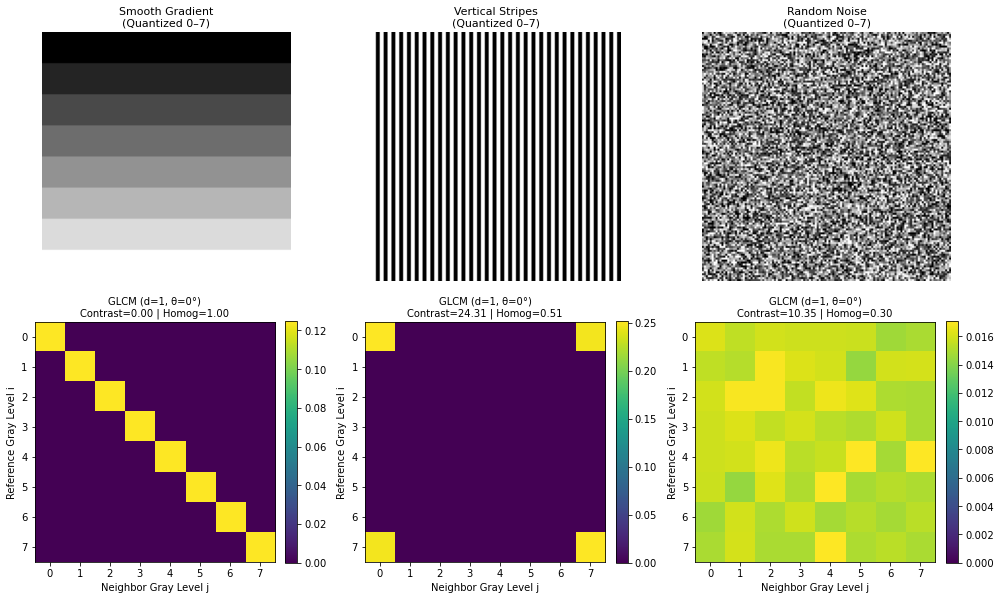

In [2]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8.5))

for col, (name, tex, P, feats) in enumerate(glcm_matrices):
    # Top row: Quantized Texture Patch
    axes[0, col].imshow(tex, cmap="gray", vmin=0, vmax=LEVELS - 1)
    axes[0, col].set_title(f"{name}\n(Quantized 0–{LEVELS - 1})", fontsize=11)
    axes[0, col].axis("off")

    # Bottom row: Symmetric Normalized GLCM Heatmap (d=1, theta=0 deg)
    im = axes[1, col].imshow(P, cmap="viridis", vmin=0)
    axes[1, col].set_title(
        f"GLCM (d=1, θ=0°)\nContrast={feats['Contrast']:.2f} | Homog={feats['Homogeneity']:.2f}",
        fontsize=10
    )
    axes[1, col].set_xlabel("Neighbor Gray Level j")
    axes[1, col].set_ylabel("Reference Gray Level i")
    axes[1, col].set_xticks(range(LEVELS))
    axes[1, col].set_yticks(range(LEVELS))
    plt.colorbar(im, ax=axes[1, col], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()